# 04 - Feature Engineering
**Project:** Customer Churn Prediction and Recommendation  
**Goal:** Select, transform, and create new features to improve model performance.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif

from src.data_loader  import load_dataset, identify_features
from src.preprocessor import clean_data, encode_target, encode_features, scale_features

sns.set_style('whitegrid')
DATA_PATH = '../data/indian_netflix_churn_dataset_v2.csv'

## 4.1 Load & Preprocess

In [3]:
df_raw = load_dataset("E:\MCA\SEM 3\Project\Customer_churn_prediction\customer_churn_project\data\indian_netflix_churn_dataset_v2.csv")
df     = clean_data(df_raw.copy())
df     = encode_target(df)
print('Shape after cleaning:', df.shape)

Loaded: 10,000 rows x 22 columns
Removed 0 duplicates
Missing after cleaning: 0
Target — Active(0): 6,858 | Churned(1): 3,142
Shape after cleaning: (10000, 22)


## 4.2 Create New Features

In [4]:
# --- Derived features ---

# 1. Revenue per watch hour  (value for money)
df['Fee_Per_Watch_Hour'] = np.where(
    df['Watch_Hours_Per_Month'] > 0,
    df['Monthly_Fee'] / df['Watch_Hours_Per_Month'],
    df['Monthly_Fee']
)

# 2. Complaint intensity  (total pain points)
df['Complaint_Intensity'] = df['Support_Tickets'] + df['Buffering_Complaints']

# 3. Engagement score  (watch hours + recommendation clicks)
df['Engagement_Score'] = df['Watch_Hours_Per_Month'] + df['Recommendation_Clicks']

# 4. Income-to-fee ratio
df['Income_Fee_Ratio'] = np.where(
    df['Monthly_Fee'] > 0,
    df['Monthly_Income'] / df['Monthly_Fee'],
    df['Monthly_Income']
)

# 5. Low satisfaction flag
df['Low_Satisfaction'] = (df['Customer_Satisfaction'] <= 2).astype(int)

# 6. High complaints flag
df['High_Complaints'] = (df['Complaint_Intensity'] >= 10).astype(int)

# 7. New customer flag  (tenure <= 6 months)
df['New_Customer'] = (df['Tenure_Months'] <= 6).astype(int)

new_features = ['Fee_Per_Watch_Hour', 'Complaint_Intensity', 'Engagement_Score',
                'Income_Fee_Ratio', 'Low_Satisfaction', 'High_Complaints', 'New_Customer']

print('New features created:')
df[new_features].head()

New features created:


,Fee_Per_Watch_Hour,Complaint_Intensity,Engagement_Score,Income_Fee_Ratio,Low_Satisfaction,High_Complaints,New_Customer
0,5.137931,12,45,384.785235,0,1,0
1,7.653846,4,69,1335.608040,0,0,0
2,14.422222,0,62,31.101695,1,0,0
3,1.655556,10,118,1112.946309,0,1,1
4,7.128571,4,88,421.494990,1,0,0


## 4.3 Correlation of New Features with Churn

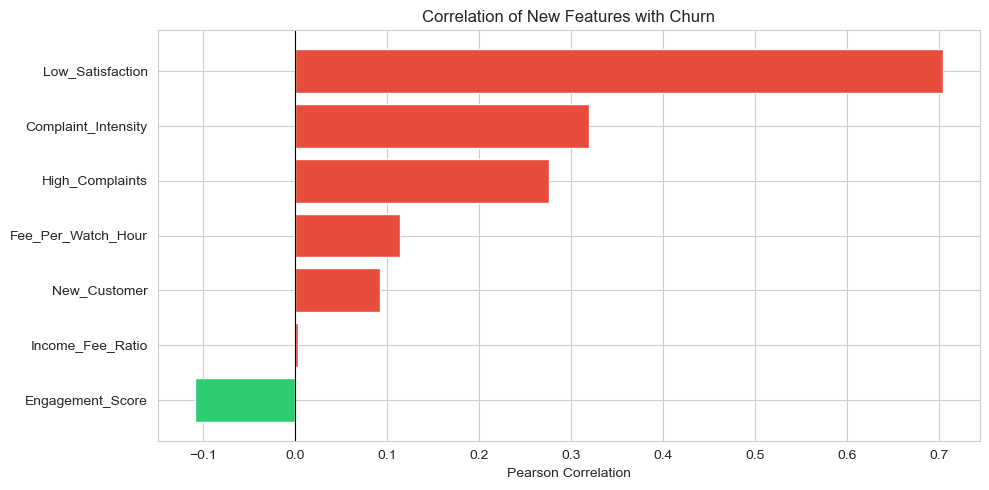

Engagement_Score      -0.109133
Income_Fee_Ratio       0.002599
New_Customer           0.091749
Fee_Per_Watch_Hour     0.113388
High_Complaints        0.275848
Complaint_Intensity    0.319765
Low_Satisfaction       0.704126
Name: Churn, dtype: float64


In [5]:
corr_new = df[new_features + ['Churn']].corr()['Churn'].drop('Churn').sort_values()

plt.figure(figsize=(10, 5))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in corr_new.values]
plt.barh(corr_new.index, corr_new.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of New Features with Churn')
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.savefig('../outputs/fe_new_feature_correlation.png', dpi=150)
plt.show()
print(corr_new)

## 4.4 Encode All Features

In [6]:
features = identify_features(df)
cat_cols  = features['categorical']
num_cols  = features['numerical'] + new_features

# Remove duplicates
num_cols = list(dict.fromkeys(num_cols))

df = encode_features(df, cat_cols)
df = scale_features(df, num_cols)

all_features = num_cols + cat_cols
print(f'Total features for modelling: {len(all_features)}')

Numerical  (17): ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months', 'Watch_Hours_Per_Month', 'Customer_Satisfaction', 'Support_Tickets', 'Buffering_Complaints', 'Concurrent_Screens', 'Recommendation_Clicks', 'Fee_Per_Watch_Hour', 'Complaint_Intensity', 'Engagement_Score', 'Income_Fee_Ratio', 'Low_Satisfaction', 'High_Complaints', 'New_Customer']
Categorical(8): ['Gender', 'State', 'City', 'Occupation', 'Subscription_Plan', 'Favorite_Genre', 'Device_Type', 'Payment_Method']
Encoded 8 categorical columns
Scaled 17 numerical columns
Total features for modelling: 25


## 4.5 Feature Importance — Random Forest

In [7]:
X = df[all_features]
y = df['Churn']

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

importance_df = pd.DataFrame({
    'Feature':    all_features,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print('Top 15 Features:')
print(importance_df.head(15).to_string(index=False))

Top 15 Features:
              Feature  Importance
Customer_Satisfaction    0.288247
     Low_Satisfaction    0.269739
  Complaint_Intensity    0.087732
      Support_Tickets    0.087711
 Buffering_Complaints    0.074374
Watch_Hours_Per_Month    0.051577
      High_Complaints    0.040162
   Fee_Per_Watch_Hour    0.020793
        Tenure_Months    0.017886
     Engagement_Score    0.014345
         New_Customer    0.008057
     Income_Fee_Ratio    0.005225
       Monthly_Income    0.004923
Recommendation_Clicks    0.004868
                  Age    0.003748


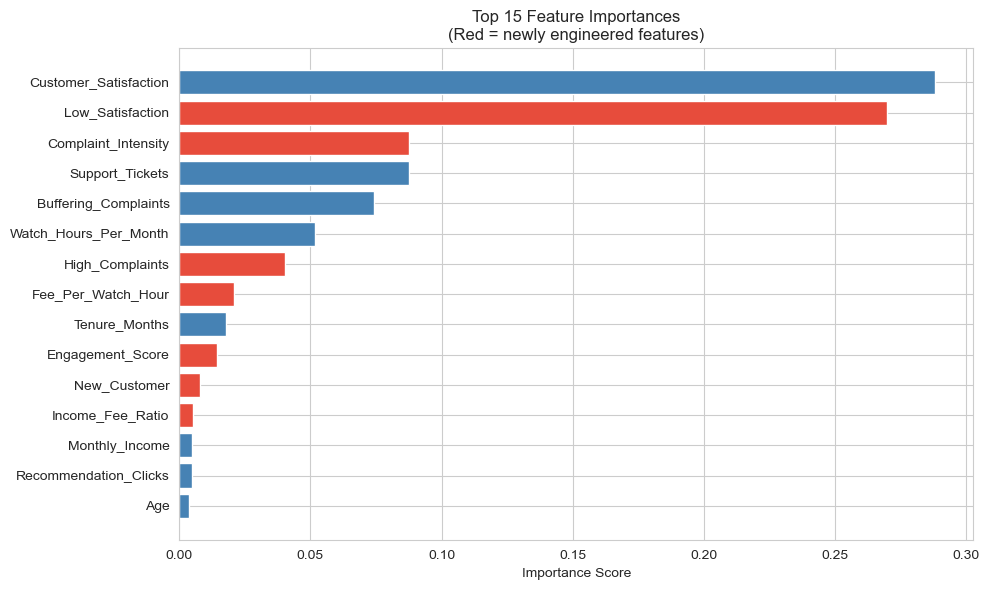

In [8]:
top15 = importance_df.head(15)

plt.figure(figsize=(10, 6))
colors = ['#e74c3c' if f in new_features else 'steelblue' for f in top15['Feature']]
plt.barh(top15['Feature'][::-1], top15['Importance'][::-1], color=colors[::-1])
plt.title('Top 15 Feature Importances\n(Red = newly engineered features)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('../outputs/fe_importance.png', dpi=150)
plt.show()

## 4.6 Mutual Information Scores

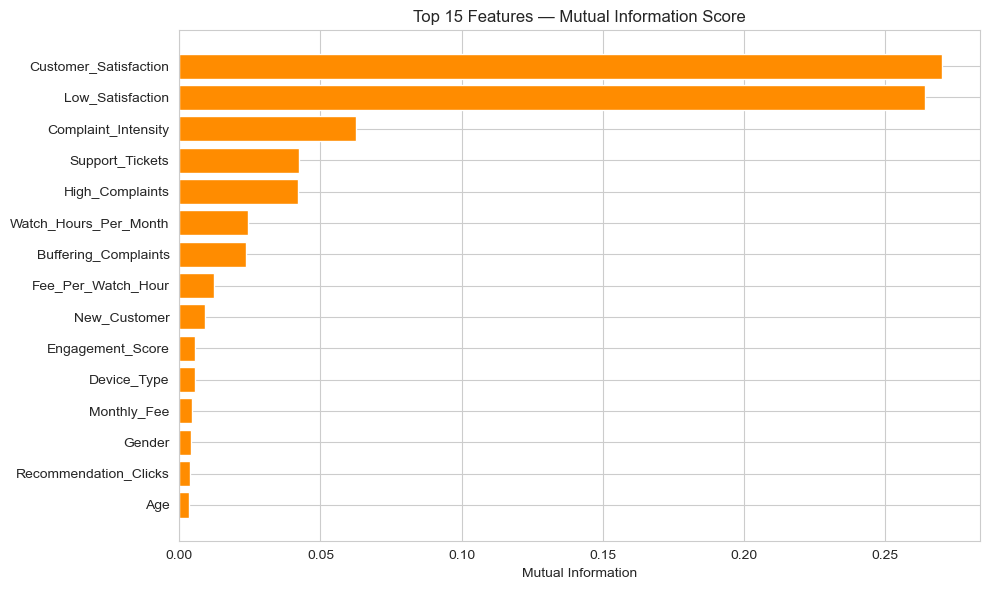

              Feature  MI_Score
Customer_Satisfaction  0.270013
     Low_Satisfaction  0.263974
  Complaint_Intensity  0.062764
      Support_Tickets  0.042448
      High_Complaints  0.042209
Watch_Hours_Per_Month  0.024295
 Buffering_Complaints  0.023739
   Fee_Per_Watch_Hour  0.012162
         New_Customer  0.008971
     Engagement_Score  0.005667
          Device_Type  0.005510
          Monthly_Fee  0.004663
               Gender  0.004193
Recommendation_Clicks  0.003904
                  Age  0.003493


In [9]:
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({'Feature': all_features, 'MI_Score': mi_scores})
mi_df = mi_df.sort_values('MI_Score', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(mi_df['Feature'][::-1], mi_df['MI_Score'][::-1], color='darkorange')
plt.title('Top 15 Features — Mutual Information Score')
plt.xlabel('Mutual Information')
plt.tight_layout()
plt.savefig('../outputs/fe_mutual_info.png', dpi=150)
plt.show()
print(mi_df.to_string(index=False))

## 4.7 Final Feature Set

In [10]:
# Select top features based on RF importance (threshold > 0.01)
selected = importance_df[importance_df['Importance'] > 0.01]['Feature'].tolist()
print(f'Selected {len(selected)} features (importance > 0.01):')
print(selected)

# Save feature list
import json, os
os.makedirs('../models', exist_ok=True)
with open('../models/selected_features.json', 'w') as f:
    json.dump({'all_features': all_features, 'selected_features': selected,
               'new_features': new_features}, f, indent=2)
print('Feature list saved to models/selected_features.json')

Selected 10 features (importance > 0.01):
['Customer_Satisfaction', 'Low_Satisfaction', 'Complaint_Intensity', 'Support_Tickets', 'Buffering_Complaints', 'Watch_Hours_Per_Month', 'High_Complaints', 'Fee_Per_Watch_Hour', 'Tenure_Months', 'Engagement_Score']
Feature list saved to models/selected_features.json


## Summary
New engineered features created:
| Feature | Description |
|---|---|
| `Fee_Per_Watch_Hour` | Monthly fee divided by watch hours — high value = low engagement |
| `Complaint_Intensity` | Support tickets + buffering complaints |
| `Engagement_Score` | Watch hours + recommendation clicks |
| `Income_Fee_Ratio` | Monthly income / monthly fee — affordability indicator |
| `Low_Satisfaction` | Flag: satisfaction score ≤ 2 |
| `High_Complaints` | Flag: complaint intensity ≥ 10 |
| `New_Customer` | Flag: tenure ≤ 6 months |

- **Next step:** Notebook 05 — ML Models